# From idea to reporting: AI assistance at each stage of glioma research

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/AI-assisted-glioma-research/blob/main/notebooks/13_research_workflow_examples.ipynb)

*In Google Colab, the first code cell clones the public repository and puts its package on the path;
Colab's own NumPy and Matplotlib are used, not the locked versions. No data are downloaded. The
optional reference check in section 2 contacts doi.org only if you switch it on.*

**Question.** Where in a research project can AI assistance help, what does that look like in glioma
research, and what must the researcher still check and decide at each stage?

**Evidence.** This notebook is a guide, not a study. It mixes kinds of evidence, and each is labelled
where it appears:
- *published results*, cited with a link, and summarised only as far as their abstracts or titles go;
- *observations from this repository's own development*, taken from the assistance records in
  `docs/ai-use/` and the validation log `docs/validation.md`;
- *one synthetic construction* (section 7), computed by the package;
- *proposed work* and a *teaching scenario*, which are plans, not studies that exist.

There are no patient data, no clinical findings and no new results. The example prompts were written
for this notebook. They are not recorded interactions, and no AI answers are shown.

**What you will learn.**
- The nine stages of a research workflow, from idea to further studies, as one researcher's slide
  lays them out, and how each stage looks in glioma research.
- Three ways of working with AI (support, collaborator, agent) and why the checks a researcher must
  make depend on the mode as much as on the stage.
- What AI assistance can do well at each stage, what typically goes wrong, and which checks cannot be
  delegated.
- Where the other notebooks of this collection (01–12) illustrate each stage, with real examples of
  AI assistance that went right and AI output that was wrong.

**How each stage is presented.** Sections 1–9 follow the slide from left to right. Each has the same
parts:
1. *What happens at this stage*, in general and for glioma.
2. *Where AI can help*, in each of the three modes.
3. *A glioma example* from the published literature.
4. *From this repository*: what actually happened while these notebooks were built.
5. *The running scenario* (see below), advanced by one stage.
6. *Pitfalls and checks*.
7. *Try it*: an exercise, often with an example prompt to adapt.

**The running scenario (teaching scenario; proposed work, not a study).** One imagined project is
followed through all nine stages, so that each stage builds on the previous one:

> *Surgery removes a glioma, but it can also cut white-matter connections. Could pre-operative
> imaging of the brain's networks help predict which patients will lose, keep or regain cognitive
> function after surgery?*

It draws on notebooks 10–12 and on a proposed design in this repository,
[`docs/cognition-prediction-study.md`](../../docs/cognition-prediction-study.md) (version 0.1, a design
for review, not an approved protocol). No such study has been carried out here.

**Who this is for.** Clinicians, neuroscientists, imaging scientists, students and modellers who want
to use AI tools in research without giving up responsibility for the result. No programming is needed
to read the notebook; the few code cells draw the figures and run two small checks.

## AI contribution and verification

**Question.** Where can AI assistance help in each of the nine stages of a glioma research project,
and what must the researcher still check and decide?

**AI contribution.**
- *Trained imaging AI*: none in this notebook. Sections 6 and 7 discuss where it enters a project.
- *Generative research assistance* (development only): on 19 October 2026 a Cursor agent (reported
  as Claude Opus 5.5; settings not captured) drafted the text of this notebook, wrote the module
  `glioma_ai.research_workflow` (the stages, the figure, the synthetic example of section 7 and the
  DOI lookup) and its tests, selected the references and checked them
  ([record](../../docs/ai-use/2026-10-19-notebook-13-research-workflow.md)).
- *Conventional code* (rerun every time, no model): the figure, the synthetic masks and their Dice
  and volumes, and the record check of section 8. Rebuilding the notebook calls no language model.
  The optional check in section 2 queries doi.org, a registry, not a language model.

**Investigator choices.** The investigator asked for a thirteenth notebook built on the nine stages of
the slide "The Research Workflow (from idea to reporting)" in their presentation, explaining and
illustrating each stage for AI-assisted glioma research. They asked for mainly markdown cells, a
didactic, example-driven style and a notebook that runs in Colab. From options the assistant
offered, they chose to redraw the slide in code (Figure 1) rather than attach the slide image, and
to track an executed copy as for notebooks 01–12. The stage names and bullet points follow the
slide.

**Design choices awaiting review** (the assistant's): the definitions of the three modes, the
running scenario, the choice of published and repository examples, the example prompts, the
assignment of notebooks to stages in Figure 1, and the summary table of section 10.

**Verification.**
- Package tests (`tests/test_research_workflow.py`): the nine stages are in the slide's order; every
  notebook and file that Figure 1 and the stage sections name exists; the synthetic example gives
  the stated disagreement between Dice and volume; the DOI lookup reads registry records correctly
  (tested offline); and the DOIs cited in this notebook are exactly the list that section 2 checks.
- On 19 October 2026 every DOI in section 11 resolved through doi.org (Crossref, or DataCite for the
  two arXiv preprints) with the cited first author and year. Statements about published work follow
  their PubMed abstracts, or only their titles where marked. The ICMJE and European Commission
  guidance was read on their web pages the same day.
- The repository examples were taken from the records in `docs/ai-use/`, `docs/validation.md` and
  the notebooks they cite.

**Evidence status.** A guide with labelled examples. No new results, and nothing here has had
clinical or independent review.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def repository_root():
    candidates = (Path.cwd(), *Path.cwd().parents)
    return next((p for p in candidates if (p / "pyproject.toml").is_file()), None)


if IN_COLAB and repository_root() is None:
    checkout = Path("/content/AI-assisted-glioma-research")
    if not checkout.is_dir():
        url = "https://github.com/arvidl/AI-assisted-glioma-research"
        subprocess.run(["git", "clone", "--depth", "1", url, str(checkout)], check=True)
    os.chdir(checkout)
    sys.path.insert(0, str(Path.cwd() / "src"))
if repository_root() is None:
    raise RuntimeError("Open this notebook in a checkout of the repository or in Google Colab.")

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from glioma_ai import research_workflow as rw
from glioma_ai.notebook_display import show_figure

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
assert rw.missing_examples(ROOT) == [], rw.missing_examples(ROOT)


def show_workflow(highlight=None, dpi=80):
    figure = plt.figure(figsize=(12, 6.8))
    rw.draw_workflow(figure, highlight=highlight)
    show_figure(figure, dpi=dpi)

## 0. The workflow, and three ways of working with AI

A research project moves from a first idea to a reported result and onwards to the next study.
Figure 1 lays out that path in nine stages, in the order of the slide it is redrawn from. Below each
stage, "NB" lists the notebooks of this collection that illustrate it.

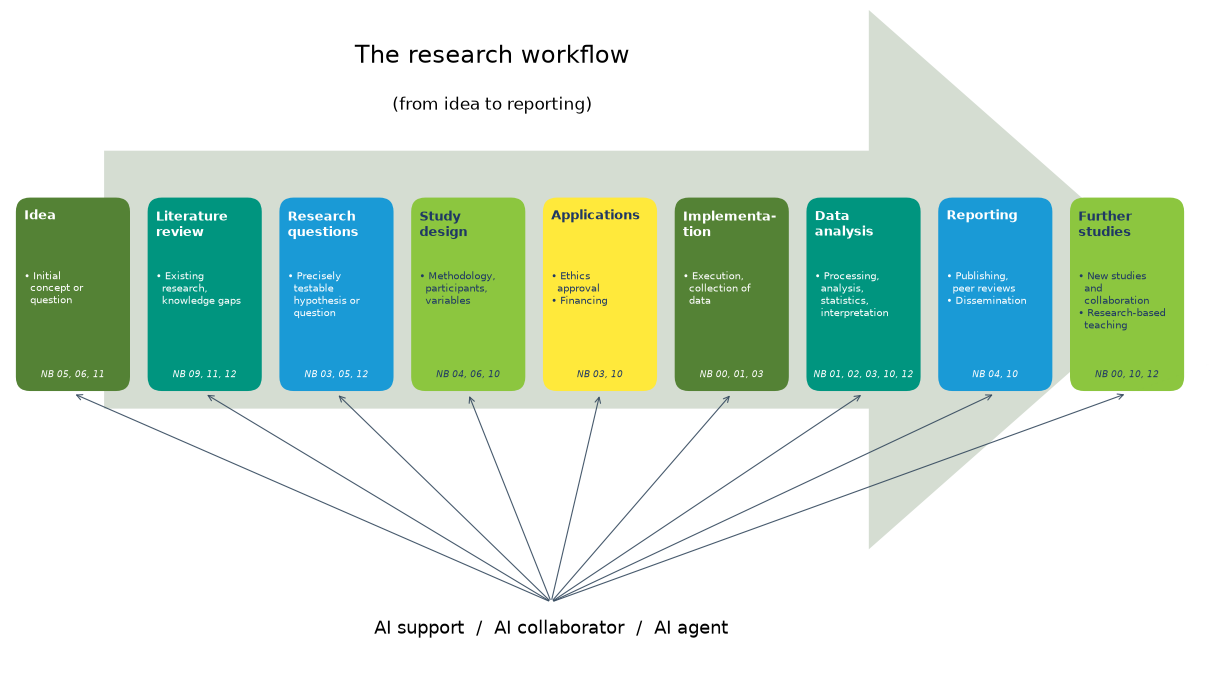

In [3]:
show_workflow(dpi=100)

**Figure 1. The research workflow from idea to further studies, with AI able to enter at every
stage.** Redrawn in code from the investigator's slide (`glioma_ai.research_workflow.draw_workflow`).
The stage names and bullets are the slide's; the notebook numbers ("NB") are this repository's
examples of each stage.

**Reading Figure 1.**
- *The arrow suggests a sequence; real projects loop.* An analysis sends you back to sharpen the
  question, a reviewer sends you back to the design, and an ethics committee can change what data you
  may collect. The stages are useful because each asks a different kind of question, not because they
  happen once each in order.
- *The lines run from AI to every stage.* AI tools can now help at any point, from brainstorming an
  idea to formatting a reference list. What changes from stage to stage is the kind of help, the
  risk, and the check that cannot be handed over.
- *Applications is the odd one out.* It is about permission and money rather than knowledge: ethics
  approval, data protection and funding. It is also where confidentiality rules on AI use are
  strictest.

### Three modes of AI involvement

The bottom of the slide names three modes: *AI support / AI collaborator / AI agents*. They differ in
how much the AI does on its own between two human decisions.

| Mode | What the AI does | Who acts | Glioma example | What the researcher must do |
| --- | --- | --- | --- | --- |
| **AI support** | Answers one bounded request: explain, summarise, translate, reformat. | The researcher does everything else. | "Explain in plain words what RANO 2.0 changed for the baseline MRI." | Check the answer against the source. |
| **AI collaborator** | Drafts, critiques and revises over several turns of a dialogue. | The researcher decides what to keep. | Sharpening a research question on connectivity and cognition through rounds of critique. | Decide; keep the reasoning; note what came from the AI. |
| **AI agent** | Plans and carries out several steps with tools: searches, writes and runs code, edits files. | The agent acts within the limits it is given. | Writing an analysis module, running its tests and executing the notebooks, as was done in this repository. | Set the limits; review every change; verify outputs independently; approve anything irreversible. |

The modes are not ranked; an agent is not "better" than a support tool. The more steps an AI takes
between two human checks, the more can go wrong unseen, so the more the result must be verified, by
tests, by reading the changes and by comparison with sources.

### Three kinds of computation

This collection keeps three kinds of computation apart, and so should a methods section:
- **Trained imaging AI**: a model trained on images that produces outputs such as tumour
  segmentations. It enters at implementation and analysis (sections 6 and 7). Its accuracy is
  measured against reference data, as in notebooks 01 and 09.
- **Generative research assistance**: language-model tools that help write code, text, figures and
  plans. They can enter at every stage. Their contribution is recorded (notebook 04) and their output
  verified.
- **Conventional code**: numerical solvers, statistics and plotting that do exactly what they are
  written to do, every time. Most of the code in these notebooks is of this kind. It needs its own
  checks: correct code is not guaranteed by having been written with or without AI.

### Rules that apply at every stage

1. **Responsibility stays with people.** AI tools cannot be authors because they cannot take
   responsibility for the work; the humans who use them are responsible for everything submitted
   ([ICMJE](https://www.icmje.org/recommendations/browse/artificial-intelligence/ai-use-by-authors.html)).
2. **Patient data stay where they are allowed to be.** Identifiable or sensitive data go only into
   tools approved for them by the data controller and ethics approval. When in doubt, use synthetic
   or public de-identified data, as these notebooks do.
3. **Fluent is not the same as correct.** AI output is often well written and confidently wrong. Check
   numbers, citations and claims against their sources (sections 2 and 8 show why).
4. **Record substantive assistance.** Say which tool did what, which checks were made and who decided.
   Notebook 04 shows the records used here.
5. **Beware of producing more while understanding less.** Messeri and Crockett (2024) argue that AI
   tools can create *illusions of understanding*, in which researchers believe they understand more
   than they do, and can narrow science into *monocultures* of methods and questions. A good test is
   whether you could explain and defend every step without the tool.

## 1. Idea: the initial concept or question

**What happens at this stage.** An idea comes from a puzzling clinical observation, a surprising
result, a new dataset or a new method. At first it is vague and broad: *Does the tumour's contact with
neurons matter for how it grows?* *Why do some patients do better cognitively after surgery than
before?* The aim of this stage is not precision but a direction worth exploring.

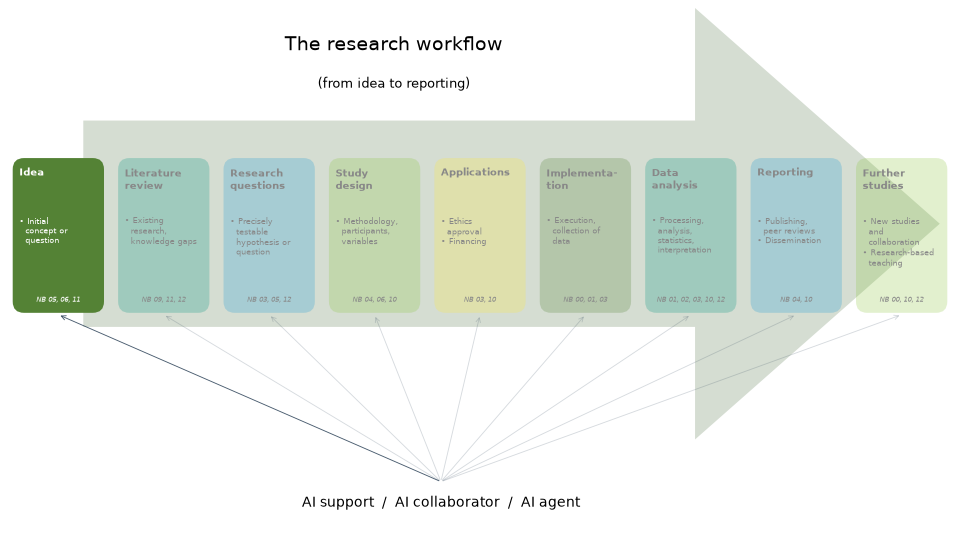

In [4]:
show_workflow(highlight=0)

**Where AI can help.**
- *Support:* get oriented in an unfamiliar field quickly ("What is a neuron–glioma synapse?"), then
  confirm with a review article.
- *Collaborator:* brainstorm competing explanations for an observation, ask the AI to argue against
  your idea, and list what data could tell the explanations apart. This is where a dialogue is most
  useful, because the value lies in the alternatives you would not have thought of.
- *Agent:* research prototypes now generate, rank and even test hypotheses with little human input
  (Lu et al. 2024, *The AI Scientist*; Gottweis et al. 2025, an AI co-scientist; both are preprints).
  Wang et al. (2023) review how AI is being used in scientific discovery more broadly. Claims that an
  idea is new or important still need the scrutiny you would give a manuscript.

**A glioma example (published result).** Venkatesh et al. (2019) found AMPA receptor-dependent
synapses between neurons and glioma cells, and found that blocking this electrochemical signalling
inhibited the growth of glioma xenografts and extended mouse survival. A finding like this opens many
ideas at once: the brain may feed the tumour, tumour activity may change the brain, and
cognition and tumour growth may be linked. Notebook 06 turns one of them into a small synthetic model
of neuron–glioma feedback.

**From this repository.** Notebook 11 began as an idea from the investigator: link the tumour growth
of notebook 02 to the cognitive testing of notebook 10, mirroring digital-twin questions such as "how
is white matter organised and how is structural connectivity disrupted?" The assistant then offered
options: an atlas or patient
connectome or a network constructed in code, and oscillator models or a linear model. The
investigator chose a constructed network and a linear model with an exact solution (notebook 11,
"AI contribution and verification"). The idea came from a person, the options from the AI, and the
choice from the person.

**The running scenario.** *Idea:* surgery removes tumour but can also cut white-matter tracts; perhaps
pre-operative network imaging could warn which patients are at risk of cognitive decline.

**Pitfalls and checks.**
- *The popular idea first.* Language models reflect what is common in their training data, so they
  tend to suggest the well-trodden idea. Ask explicitly for minority views and for evidence against.
- *Novelty claims.* "This has not been studied" is a claim about the literature that the AI may not be
  able to know. Check it in section 2.
- *Plausible is not true.* A mechanism that sounds right is still a hypothesis.

**Try it.** Adapt this example prompt (written for this notebook; not a recorded interaction):

> *I study diffuse glioma. Some patients improve on cognitive tests after resection and others
> decline. List three competing explanations. For each, name one measurement that would distinguish it
> from the other two. Give references only if you are certain they exist, with DOIs; I will check
> every one.*

Then judge the answer: are the explanations really different, or one idea in three wordings? Can each
measurement be made in practice? Do the references exist (section 2)?

## 2. Literature review: existing research and knowledge gaps

**What happens at this stage.** You find, read, appraise and summarise what is known, and you
identify the gap that your question will fill. In glioma research the literature spans molecular
pathology, imaging, surgery, neuropsychology and modelling, so few people can review all of it
unaided.

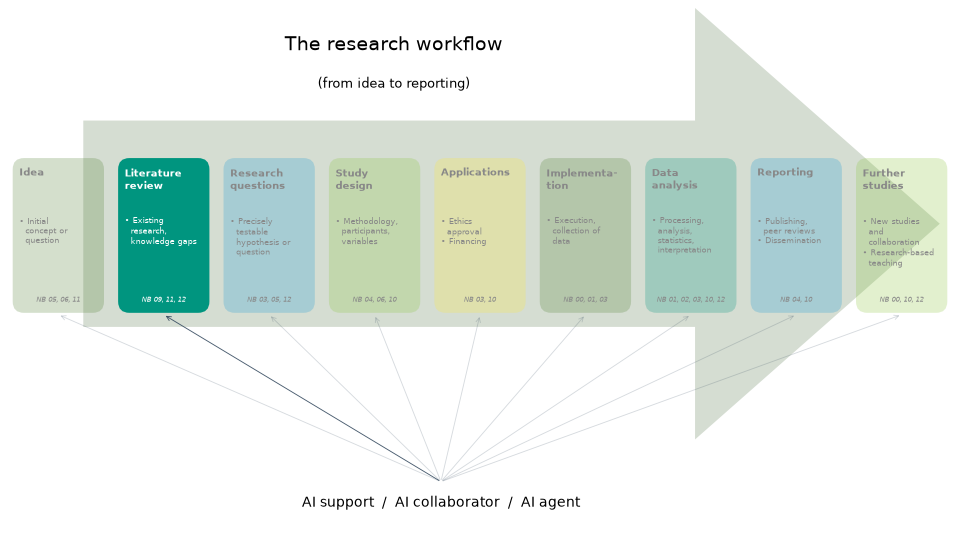

In [5]:
show_workflow(highlight=1)

**Where AI can help.**
- *Support:* summarise an abstract, explain a method, translate a paper.
- *Collaborator:* design a search strategy (databases, controlled vocabulary such as MeSH terms,
  inclusion criteria), build a comparison table of studies, critique your statement of the gap.
- *Agent:* tools that search databases, read full texts and assemble evidence tables. They save time,
  and their output must be checked like a student's first draft.

**The main risk: references that do not exist or do not say what is claimed.** Walters and Wilder
(2023) asked ChatGPT-3.5 and ChatGPT-4 for short literature reviews on 42 topics and checked the 636
citations. 55% of the GPT-3.5 citations and 18% of the GPT-4 citations were fabricated, and among
the real ones, 43% and 24% contained substantive errors. Newer and search-based tools may do better,
but the check stays the same: resolve every DOI and read at least the abstract of every cited work.

**Glioma examples (published results): read the design, not only the headline.**
- Capper et al. (2018) presented a machine-learning classifier of DNA methylation profiles for
  central nervous system tumours; in their routine diagnostic setting it changed the diagnosis in up
  to 12% of prospective cases.
- Hollon et al. (2020) combined stimulated Raman histology with deep convolutional neural networks to
  predict brain-tumour diagnosis in the operating room in under 150 s; in a multicentre prospective
  trial of 278 patients, accuracy was 94.6% against 93.9% for pathologists reading conventional
  histology (non-inferior).
- Kickingereder et al. (2019) used artificial neural networks to segment tumours automatically and
  compared the resulting volumetric time to progression with that assessed by RANO, including in
  multicentre data from the EORTC-26101 trial.

Each is a trained AI model evaluated in a stated design (retrospective, prospective, multicentre). A
literature review should record that design, because it limits what the result means.

**From this repository.** Two errors were caught by checking references against registries:
- The request for notebook 12 named the first author of an article as "W.K. Miller"; the article's
  first author is Earl K. Miller
  ([record](../../docs/ai-use/2026-10-15-notebook-12-tracks.md)).
- A title carried over from notebook 11, Aerts et al. (2022), read "multimodal MRI data"; the
  published title says "multimodal magnetic resonance imaging data". Notebook 12 has the corrected
  title.

The paper's references, and the reference lists of the notebooks, were resolved through registries
and compared with title, first author and year, as recorded in the
[bibliography check](../../docs/bibliography-check.md) and the validation log. The cell below lets you do
the same for this notebook.

**The running scenario.** *Literature:* reviews of cognition after glioma surgery, structural and
functional connectivity in glioma, and public datasets with pre- and post-operative imaging and
cognitive tests, such as the Brain Tumor Connectomics data used in notebooks 10 and 12 (Aerts et al.
2022). *Gap, to be confirmed by the review:* few studies test whether network measures add
predictive information beyond baseline cognition.

**Pitfalls and checks.**
- *Fabricated or garbled references:* resolve every DOI.
- *Citation context:* a real paper cited for something it does not say. Read the abstract, and the
  relevant section for key claims.
- *Recency:* a model's training data end at some date; recent work may be missing.
- *Copyright and confidentiality:* do not upload paywalled full texts or unpublished manuscripts to
  tools whose terms do not allow it.

**Try it.** Run the cell below with `CHECK_DOIS = True` (in Colab or locally with internet access). It
looks up each DOI of section 11 at doi.org and compares the first author and year with the citation.
Then try it on a reference list an AI tool gave you: change one year or author and see the check
fail.

In [6]:
CHECK_DOIS = False  # set to True to query doi.org (internet access needed)

if CHECK_DOIS:
    rows = ["| DOI | Registry first author, year | Result |", "| --- | --- | --- |"]
    for doi, author, year in rw.NOTEBOOK_DOIS:
        try:
            record = rw.doi_metadata(doi)
            problems = rw.check_reference(author, year, record)
            found = f"{record['first_author']}, {'/'.join(map(str, record['years']))}"
            rows.append(f"| {doi} | {found} | {'; '.join(problems) or 'agrees'} |")
        except OSError as error:
            rows.append(f"| {doi} | not reached | {error} |")
    display(Markdown("\n".join(rows)))
else:
    print(f"Reference check of {len(rw.NOTEBOOK_DOIS)} DOIs not run; set CHECK_DOIS = True.")

Reference check of 24 DOIs not run; set CHECK_DOIS = True.


## 3. Research questions: a precisely testable hypothesis or question

**What happens at this stage.** The idea becomes a question that data can answer. A good question
names the population, the exposure or predictor, the comparison, the outcome with its unit, and the
time point, and it says whether the aim is to *describe*, to *predict* or to *explain* (find a cause).
These aims need different designs and permit different conclusions.

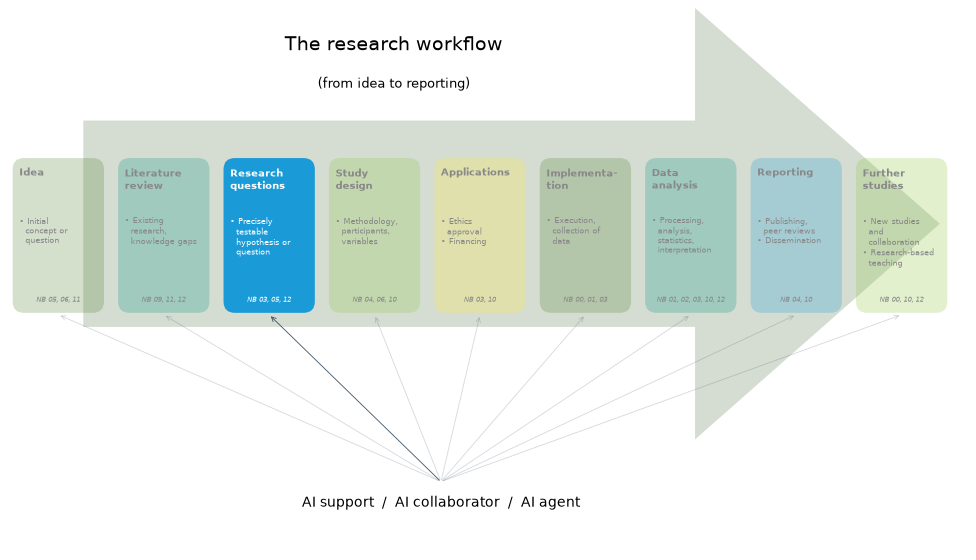

In [7]:
show_workflow(highlight=2)

**Where AI can help.**
- *Collaborator:* this is the best use. Ask the AI to find undefined terms, hidden assumptions,
  missing units and confounders, and to say what result would *disprove* the hypothesis.
- *Support:* rephrase a question for a lay summary or another discipline.
- *Agent:* rarely appropriate. Choosing the question is the researcher's job.

**Vague and testable, three glioma examples.**

| Vague | Testable | Where in this collection |
| --- | --- | --- |
| Is the AI segmentation good? | For enhancing tumour in a public cohort, what are the Dice overlap and the relative volume error of the model against reference masks, and do they rank cases the same way? | Notebook 01 (and section 7 below) |
| Does the tumour spread along white matter? | In a reaction–diffusion model with faster migration in white matter, how much tumour reaches the other hemisphere through the corpus callosum within a year, and how does that depend on the migration rates? | Notebooks 02 and 11 (synthetic) |
| Does surgery affect the brain network? | In one patient, how much pre-operative structural connectivity runs through streamlines that cross the tumour, and how does a virtual resection of them compare with the measured post-operative network? | Notebook 12 (one patient, descriptive) |

**A glioma example (published result).** Definitions change. The 2021 WHO classification of central
nervous system tumours (Louis et al. 2021) integrates molecular markers into diagnosis, so a question
about "grade II glioma" written with older labels may not correspond to a current diagnosis. The
proposed design in this repository therefore warns against reinterpreting historical grades as modern
molecular diagnoses.

**From this repository.** Every notebook states its question in its first cell, and several notebook
titles are questions: "Can a glioblastoma change without growing?" (05), "Does a glioma feed its own
growth?" (06). For notebook 12 the assistant proposed three alternative titles and the investigator
chose "Can a virtual resection predict one patient's post-operative brain network?"
([record](../../docs/ai-use/2026-10-15-notebook-12-tracks.md)). The question now states its own limit:
*one* patient.

**The running scenario.** *Question* (from the proposed design): in adults with diffuse glioma
undergoing resection, do pre-operative network features improve prediction of spatial working-memory
span (CANTAB SSP, in boxes) at a prespecified follow-up, beyond baseline span, clinical information and
tumour anatomy? It is a *prediction* question: even a good predictor would not show that surgery or
disconnection *caused* the change.

**Pitfalls and checks.**
- *A question shaped by the data at hand* rather than by what matters. Write the question before
  looking at what is available, then record any change.
- *Precise-sounding but undefined.* "Cognitive outcome" is not an outcome until test, score, unit and
  time point are named. AI rewording can make a question sound precise while leaving such terms open.
- *Hypothesising after the results are known.* Fix the question, and if possible register it, before
  the analysis.

**Try it.** Example prompt (written for this notebook):

> *Here is my research question: [paste]. Act as a critical reviewer. List every term that is not
> operationally defined, every unit that is missing, and every plausible confounder. Is the aim
> description, prediction or causal explanation? What result would count against my hypothesis?*

Apply it to the scenario's question above. Which of the AI's objections would you accept, and why?

## 4. Study design: methodology, participants and variables

**What happens at this stage.** You decide how the question will be answered: the design
(retrospective cohort, prospective study, trial, simulation), who is eligible, which variables are
measured, in which units and when, the comparisons and baselines, the sample size and the analysis
plan. A design is good when its result would change your mind whichever way it comes out.

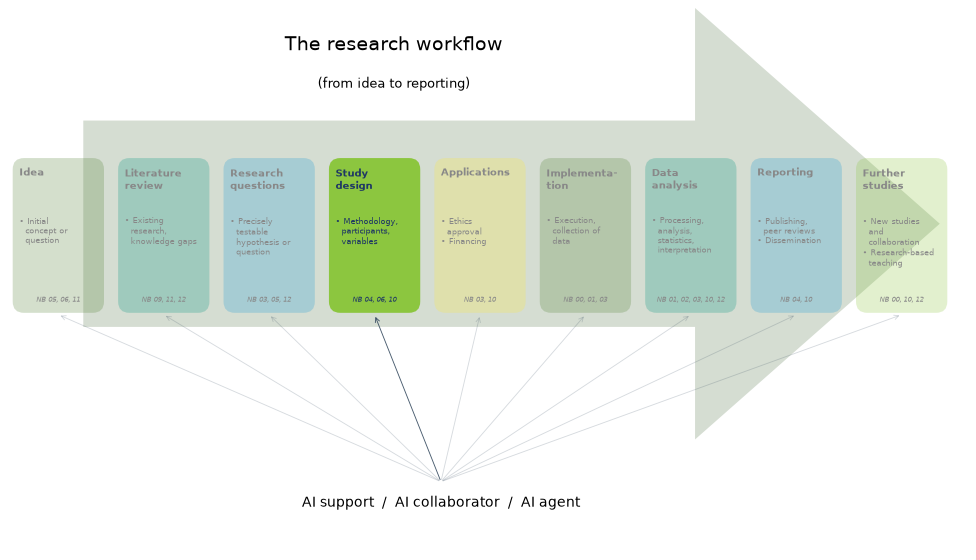

In [8]:
show_workflow(highlight=3)

**Where AI can help.**
- *Collaborator:* list confounders and sources of bias, draft an analysis plan, check that every
  predictor is available before the outcome, and play the hostile reviewer.
- *Agent:* run simulations to choose a sample size under stated assumptions, or write a data
  dictionary from a protocol.
- *Support:* explain a design term (estimand, nested cross-validation, reliable change).

**Glioma examples (published results).**
- *When to measure.* RANO 2.0 (Wen et al. 2023) recommends the post-radiotherapy MRI, not the
  post-surgical one, as the baseline in newly diagnosed glioma, and because pseudoprogression is
  common in the 12 weeks after radiotherapy, it requires confirmation of progression in that period.
  Choices like these decide what a "change" in a study means.
- *Leakage.* Kapoor and Narayanan (2023) found data leakage in 294 papers across 17 fields that use
  machine learning, sometimes leading to wildly over-optimistic conclusions, and described eight types.
  In a glioma imaging study, typical leaks are scans of the same patient in both training and test
  sets, normalisation computed on all data before splitting, and predictors measured after the
  outcome.

**From this repository.**
- *Baselines and controls.* Notebook 10 shows that simply carrying the baseline score forward
  (persistence) is a demanding baseline for forecasting follow-up cognition. Notebook 06 compares
  three nested assumptions, no coupling, one-way coupling and feedback, with everything else fixed.
- *Checks that could fail.* Notebook 04 derives checks from the equations alone and shows, with
  deliberately faulty code, that each check catches a different fault and none catches all.
- *Proposed, not performed.* The [benefit protocol](../../docs/ai-benefit-evaluation.md) describes how one
  could measure whether AI assistance helps (matched tasks, done with and without assistance in
  counterbalanced order, with independent review). It has not been carried out, so these notebooks
  make no claim that AI assistance saved time or improved quality.

**The running scenario.** *Design* (from the [proposed design](../../docs/cognition-prediction-study.md)):
compare nested models: persistence (baseline SSP only), then clinical baseline, then tumour anatomy,
then network features. Only information available before surgery may be used as a predictor;
post-operative treatment and the measured resection cavity are excluded. The existing public cohort
is small, so it can support a demonstration and planning, not a claim of predictive performance;
sample size is to be chosen by simulation before a larger linked cohort is collected.

**Pitfalls and checks.**
- *Invented effect sizes.* An AI asked for a sample size will produce a number. Ask what effect size,
  variance and correlation it assumed, and where they came from.
- *Designs that ignore what data exist.* Check every variable against the actual data dictionary.
- *Leakage:* for every predictor, ask "when was this known?"

**Try it.** Describe this flawed design to an AI tool and ask it to find the problems, then compare
with your own list: *"We normalised all tumour volumes to the cohort mean, selected the 10 best of 200
network features on all patients, then estimated accuracy with 5-fold cross-validation. Follow-up
tumour volume was included as a predictor."* (There are at least three leaks.)

## 5. Applications: ethics approval and financing

**What happens at this stage.** Before data are collected, the project needs permission and money.
In Norway, medical and health research on people, human biological material or health information
requires prior approval by a Regional Committee for Medical and Health Research Ethics
([REK](https://rekportalen.no/)) under the
[Health Research Act](https://lovdata.no/dokument/NL/lov/2008-06-20-44) (helseforskningsloven).
Data protection under the GDPR, agreements with data controllers, and the licences of any public
datasets also belong here, as do grant applications.

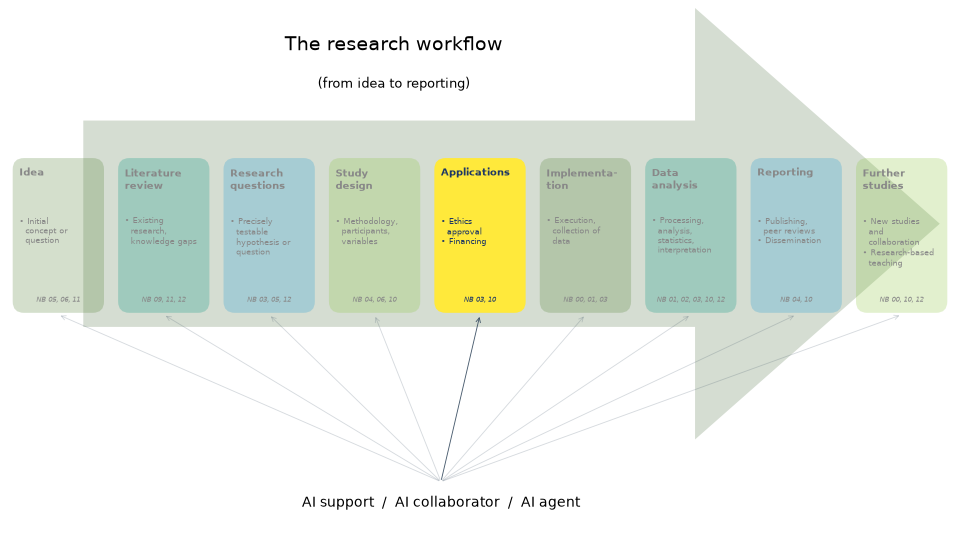

In [9]:
show_workflow(highlight=4)

**Where AI can help.**
- *Support:* translate between Norwegian and English, shorten text to a word limit, check that a
  budget table adds up.
- *Collaborator:* draft a lay summary from your protocol, check the application against the protocol
  for inconsistencies, list the sections a call requires, and anticipate a committee's questions
  about consent, risk and data security.
- *Agent:* little to do here, and much to avoid. The documents are often confidential.

**What not to do.**
- Do not put identifiable patient information, or other people's confidential applications, into a
  tool that is not approved for them.
- Do not let AI invent preliminary results, letters of support or references.
- Follow the rules of your institution, funder and ethics committee on AI use, which change; check
  the current version. The European Commission's
  [guidelines on the responsible use of generative AI in research](https://research-and-innovation.ec.europa.eu/news/all-research-and-innovation-news/guidelines-responsible-use-generative-ai-research-developed-european-research-area-forum-2024-03-20_en)
  (European Research Area Forum, March 2024) say that researchers should refrain from using
  generative AI tools in sensitive activities such as peer review or evaluations, and should respect
  privacy, confidentiality and intellectual property.

**From this repository.** No ethics application was needed for these notebooks: they use synthetic
data or public, de-identified datasets under their stated terms. Checking those terms is part of this
stage, and it was not trivial:
- *LUMIERE* (notebook 03; Suter et al. 2022): on 10 October 2026 the files on Figshare were each
  labelled CC0, but the article's usage notes and the authors' README restrict use to non-commercial
  purposes. Notebook 03 and the data release state that condition, and the derived files are not
  covered by the code's MIT licence ([validation log](../../docs/validation.md)).
- *UCSF-PDGM* (notebooks 01 and 09; Calabrese et al. 2022): CC BY 4.0 and the TCIA data usage policy.
- *Brain Tumor Connectomics* (notebooks 10 and 12; Aerts et al. 2022): CC0 on OpenNeuro.

See [data and provenance](../../docs/data.md). The proposed cognition study would need ethics approval
before any new data were collected; it has none.

**The running scenario.** *Applications:* a REK application for linking pre-operative MRI, surgery
dates and repeated cognitive tests; a data protection impact assessment; an agreement on where the
data are stored and processed; and a grant application whose preliminary work is limited to what
exists (public-data notebooks and a design), stated as such.

**Pitfalls and checks.**
- *Confidentiality:* the strictest rule of all stages.
- *Overclaiming:* AI-polished grant text tends to promise more than the preliminary data support.
  Check every claim against what you have actually done.
- *Licence terms:* read the article and the data portal; they may differ.

**Try it.** Example prompt (written for this notebook):

> *Write a 150-word lay summary in Norwegian (bokmål) of the following study design for an ethics
> committee [paste the design, without any patient information]. Do not add aims, methods or benefits
> that are not in the text. Then list any statement in your summary that goes beyond the design.*

Check the second part yourself: did the summary promise a benefit to patients that the design does
not test?

## 6. Implementation: execution and collection of data

**What happens at this stage.** The study is carried out: participants are recruited, MRI is acquired
with a fixed protocol, cognitive tests are given, and data are stored, labelled and checked. Good
practice is to store data in a shared structure such as BIDS for neuroimaging (Gorgolewski et al.
2016), make them findable, accessible, interoperable and reusable where permitted (FAIR; Wilkinson et
al. 2016), and record the provenance of every file.

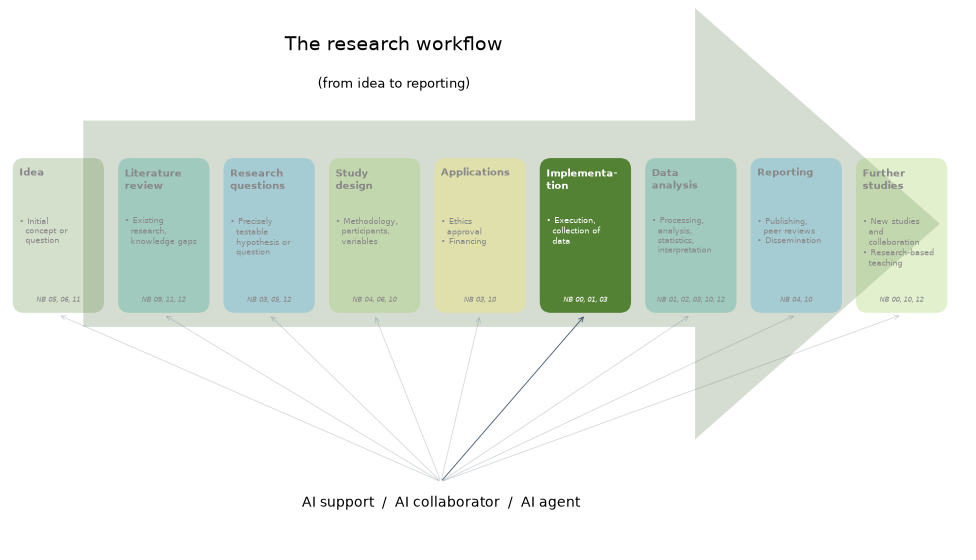

In [10]:
show_workflow(highlight=5)

**Where trained imaging AI enters.** Segmentation models turn images into labelled tumour
compartments. nnU-Net, for example, configures its own preprocessing, architecture and training for
a new segmentation task (Isensee et al. 2021). Our own published study evaluated deep-learning
segmentation of glioma and its surroundings on multiparametric MRI (Lundervold et al. 2026; notebook
09). Automated labels are measurements with errors, not ground truth; record which model and version
produced them.

**Where generative AI can help.**
- *Agent:* write scripts that download data and check their SHA-256 checksums, convert files to BIDS,
  and report missing or inconsistent files. Give the agent read-only access to raw data.
- *Collaborator:* draft the data dictionary and the quality-control checklist.
- *Support:* explain a DICOM header field or a scanner parameter.

**From this repository.**
- *Acquisition is an explicit step.* Default commands never download data. `make lumiere-fetch`
  range-reads 36 pinned Patient-048 files (about 38 MB) from the 32.6 GB LUMIERE archive, and each
  data release is pinned by SHA-256 in `src/glioma_ai/references/`, for example
  [`lumiere_bundle_p048.json`](../../src/glioma_ai/references/lumiere_bundle_p048.json).
- *Nothing is silently changed.* Notebook 01 refuses to compare label maps whose voxel-to-world
  geometry differs, instead of silently resampling one of them; the code does not register,
  threshold or relabel without saying so. See [reproducibility](../../docs/reproducibility.md).
- *Automated labels stay labelled as automated.* The LUMIERE tumour labels in notebook 03 come from
  an automated pipeline, and the notebook reads them as such, not as expert truth.

**The running scenario.** *Implementation:* pre-operative structural and diffusion MRI, resting-state
fMRI and CANTAB tests at baseline and at a prespecified follow-up, stored in BIDS; tumour masks from a
named segmentation model, reviewed by a neuroradiologist; surgery dates recorded, because the interval
between tests matters.

**Pitfalls and checks.**
- *Silent processing:* resampling, registration or thresholding without a record.
- *Units and coordinates:* millimetres or voxels, mL or mm³, which coordinate system.
- *An agent with write access to raw data.* Keep raw data read-only and versioned.
- *Device substitution:* code that silently falls back from GPU to CPU, or to a different model.

**Try it.** Open [`lumiere_bundle_p048.json`](../../src/glioma_ai/references/lumiere_bundle_p048.json).
What does a SHA-256 checksum protect against, and what does it not protect against (for example, a
correctly downloaded file with wrong labels)?

## 7. Data analysis: processing, analysis, statistics and interpretation

**What happens at this stage.** Data are processed, analysed and interpreted. This is where AI agents
are most productive today, writing and running analysis code in minutes, and where errors are
hardest to see, because wrong code often runs without complaint and produces plausible numbers.

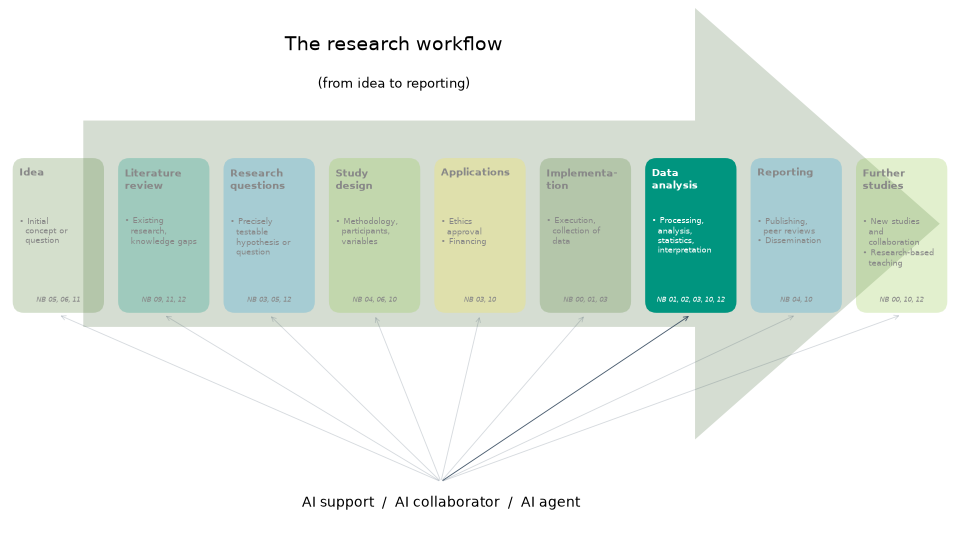

In [11]:
show_workflow(highlight=6)

**Where AI can help.**
- *Agent:* write analysis code with tests, run it, and produce figures, in a repository where every
  change can be reviewed.
- *Collaborator:* propose sensitivity analyses and alternative explanations, and critique your
  interpretation.
- *Support:* explain a statistic or an error message.

**A worked example (synthetic construction): one segmentation, two metrics, two answers.** The cell
below builds a reference "tumour", a sphere of radius 10 mm on a 1 mm grid, and two candidate
segmentations. One has exactly the right size but is shifted by 6 mm. The other is centred correctly
but has a radius 1 mm too large. It computes the Dice overlap and the relative volume error of each
with the package functions of notebook 01.

In [12]:
rows = rw.overlap_volume_example()
table = [
    "| Candidate | Reference (mL) | Candidate (mL) | Volume error | Dice |",
    "| --- | --- | --- | --- | --- |",
]
for row in rows:
    table.append(
        f"| {row['candidate']} | {row['reference_ml']:.2f} | {row['candidate_ml']:.2f} "
        f"| {row['volume_error']:+.0%} | {row['dice']:.2f} |"
    )
display(Markdown("\n".join(table)))

| Candidate | Reference (mL) | Candidate (mL) | Volume error | Dice |
| --- | --- | --- | --- | --- |
| same size, shifted 6 mm | 4.22 | 4.22 | +0% | 0.56 |
| same centre, radius +1 mm | 4.22 | 5.62 | +33% | 0.86 |

**Reading the table.** The shifted candidate has a perfect volume and poor overlap; the enlarged one
has good overlap and a volume one third too large. Which is "better" depends on the question. For
tumour volume and growth rate, the volume error matters; for planning radiotherapy or a resection
margin, the location matters. A metric answers one question; choose it from the research question
(section 3), not after seeing which one looks best. Notebook 01 shows the same point on real
segmentations of a public cohort.

**A glioma example (published result).** Kickingereder et al. (2019), cited in section 2, did not stop
at segmentation accuracy: they asked whether automated volumetric time to progression was more
reliable than the standard assessment, and how it related to overall survival, a choice of metric
driven by a clinical question.

**From this repository.**
- *A model that failed, reported as such.* In notebook 03, a baseline growth model started from one
  patient's earlier scan predicted the later scan no better than the simple prediction that nothing
  changes. The notebook keeps that failure before showing a revised model.
- *Checks that catch different faults.* Notebook 04 runs deliberately faulty solvers through three
  checks; each check catches a different fault, and none catches all.
- *Verdicts that depend on the method.* In notebook 10, whether one patient's cognitive change counts
  as "reliable" depends on which change index is used and on single people in the reference group.
- *An agent diagnosing infrastructure.* When the notebook checker stalled intermittently, an AI agent
  read the installed library code, showed with a direct test that the cell timeout could never fire
  in the way the runner used it, reproduced the stall under load and fixed the runner. It recommended
  a dependency upgrade, which the investigator approved separately
  ([record](../../docs/ai-use/2026-10-15-notebook-runner-stall.md)).

**The running scenario.** *Analysis:* fit the nested models of section 4 with patient-level
cross-validation, report errors in span units (boxes), compare with persistence, and show
uncertainty. With a small sample, report a demonstration, not performance.

**Pitfalls and checks.**
- *Code that runs but is wrong.* Test it against cases with known answers, as notebooks 02 and 04 do.
- *Checks that cannot fail.* A test that passes whatever the code does proves nothing.
- *Many analyses at machine speed.* An agent can try a hundred analyses in minutes. Prespecify the
  primary analysis and report the others as exploratory.
- *Interpretation beyond the data,* for example a general claim from one patient.

**Try it.** In the cell above, change the shift or the radius by calling
`rw.overlap_volume_example(radius_mm=8)`. Find a candidate with Dice above 0.8 and a volume error
above 40%. What would each metric tell a clinician?

## 8. Reporting: publishing, peer review and dissemination

**What happens at this stage.** Results are written up, reviewed and shared: manuscripts, figures,
code and data, talks and slides. Reporting guidelines list what readers need to judge a study, for
example TRIPOD+AI for clinical prediction models that use regression or machine learning (Collins et
al. 2024) and CLAIM for AI in medical imaging (Tejani et al. 2024).

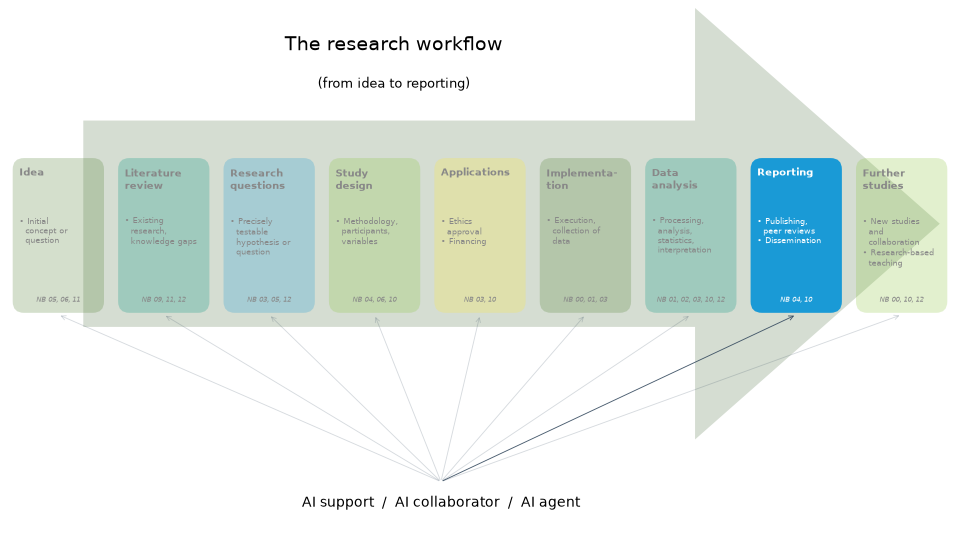

In [13]:
show_workflow(highlight=7)

**Rules on AI in publishing.** The [ICMJE recommendations](https://www.icmje.org/recommendations/browse/artificial-intelligence/ai-use-by-authors.html)
ask journals to require authors to disclose AI use and describe it; AI tools should not be listed as
authors, because they cannot be responsible for the accuracy, integrity and originality of the work;
and authors must review AI-generated content, because it can be incorrect, incomplete or biased.
Reviewers [must keep manuscripts confidential](https://www.icmje.org/recommendations/browse/artificial-intelligence/ai-use-by-reviewers.html),
which may rule out uploading them to AI tools, and should disclose any AI use to the journal. Thorp
(2023) set out *Science*'s position in an editorial titled "ChatGPT is fun, but not an author".

**Where AI can help.**
- *Support:* language editing, shortening, formatting references (then check them, section 2).
- *Collaborator:* check a manuscript against a reporting checklist, find claims that the results do
  not support, draft a plain-language summary. Liang et al. (2024) analysed at scale whether large
  language models give useful feedback on research papers (cited for its title).
- *Agent:* rebuild every figure and number from code, so that the manuscript cannot drift from the
  analysis.

**Glioma-adjacent example (published result).** Gao et al. (2023) asked ChatGPT to write abstracts from
the titles of articles in high-impact medical journals. Blinded human reviewers identified 68% of the
generated abstracts as generated, and wrongly judged 14% of the original abstracts to be generated.
Fluent scientific text is no longer evidence that a person wrote it, or that its data exist.

**From this repository.**
- *An erroneous AI-generated slide, audited.* Notebook 10 shows, unmodified and labelled as
  erroneous, a slide summarising one patient's CANTAB scores that was generated with an AI assistant
  for a presentation. Compared with the source, its bars for RVP A′, SOC and SSP show values (158, 296
  and 830) that those measures cannot take, one score is wrong, percentages contradict the slide's
  own bars, and it calls changes "significant" without any test. The notebook then rebuilds the slide from the
  released scores.
- *Numbers come from code, not from typing.* The paper's figures and numbers are generated by `make
  paper-assets` and are never pasted into [`paper/main.tex`](../../paper/main.tex) by hand.
- *Assistance is recorded honestly.* The records in `docs/ai-use/` say "model and settings not
  captured" when they were not, and keep work marked as pending review until a person has reviewed it
  ([recording AI assistance](../../docs/ai-workflow.md)).

A record validator enforces the form of such a record, not its truth. The cell below checks one of
the repository's records, then a constructed copy (made in this cell, not a real record) that claims
a human decision without naming the reviewer.

In [14]:
from glioma_ai.assistance import validate_record

record = json.loads((ROOT / "docs/ai-records/2026-10-06-explicit-ai-roles.json").read_text())
validate_record(record)
print("Repository record:", record["record_type"], "|", record["decision"])

constructed = {**record, "decision": "accepted", "reviewer": None}
try:
    validate_record(constructed)
except ValueError as error:
    print("Constructed copy refused:", error)

Repository record: retrospective_summary | pending_human_review
Constructed copy refused: A human decision requires a named reviewer.


**The running scenario.** *Reporting:* follow TRIPOD+AI; report the persistence baseline next to every
model; state the sample size and its limits; describe AI assistance in the methods (which tool, what
it did, how it was checked); share code, and data where the approvals allow.

**Pitfalls and checks.**
- *AI-made figures and summaries with wrong numbers:* check every number against the source, as in
  notebook 10.
- *Undisclosed AI use:* may be treated as misconduct in some circumstances (ICMJE).
- *Confidential manuscripts in AI tools* during peer review.
- *Statistical words without statistics:* "significant", "improved", "predicts".

**Try it.** Take an abstract you have written. Ask an AI tool to list every claim in it and say for
each whether a reader could verify it from your results section. Then check its list against
TRIPOD+AI or CLAIM yourself.

## 9. Further studies: new studies, collaboration and research-based teaching

**What happens at this stage.** Results raise new questions, invite replication and collaboration,
and feed teaching. Shared code and data make it possible for others to check, reuse and extend the
work, and research-based teaching passes on not only results but the habits that produced them.

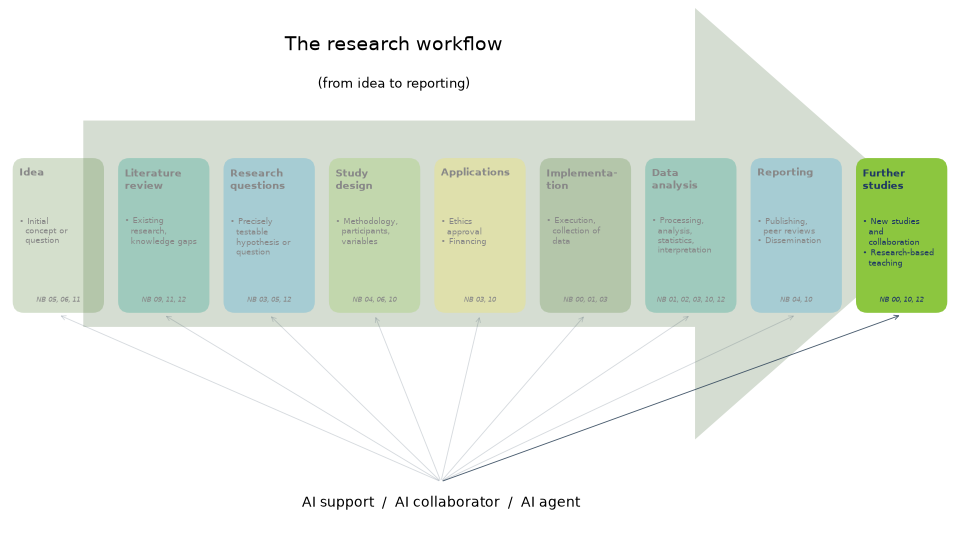

In [15]:
show_workflow(highlight=8)

**Where AI can help.**
- *Collaborator:* turn the limitations of a study into concrete next questions; draft data-sharing
  documentation; adapt teaching material for different audiences (the clinical and modelling tracks
  of notebooks 04–12 are an example).
- *Agent:* port notebooks to new platforms, keep tests and continuous integration working, and
  update code when libraries change, all under review.
- *Support:* a tutor for students, provided they learn to verify what it says.

**From this repository.**
- *Next studies, stated as proposals.* The [proposed cognition study](../../docs/cognition-prediction-study.md)
  requires a larger linked glioma cohort and ethics approval; notebook 12 ends with limits and next
  steps for its one-patient analysis; the [benefit protocol](../../docs/ai-benefit-evaluation.md) would
  test whether AI assistance helps. None of these has been carried out.
- *Teaching material that runs without installation.* Every notebook opens in Google Colab and runs
  on a CPU. The public inputs they need are pinned releases, and the few cells that need local inputs
  say so instead of substituting anything ([notebook map](README.md)).
- *Errors kept for teaching.* The audited slide of notebook 10 and the failed baseline model of
  notebook 03 are kept, because seeing how things go wrong teaches more than polished results.

**The running scenario.** *Further studies:* if network features add information, test them in an
independent cohort; if they do not, ask whether better measurements (for example
electrophysiological recordings) or better outcomes are needed. In either case, share the code and the
analysis plan, and turn the project into a teaching case.

**Pitfalls and checks.**
- *Skills that fade.* If students and researchers let AI do the reasoning, they may lose the ability to
  check it (Messeri and Crockett 2024). Teach verification habits explicitly.
- *Errors that spread.* Teaching material and shared code are copied; an error in them is copied too.
- *Collaboration without records.* When several people and several AI tools contribute, keep track of
  who did what.

**Try it.** Choose one notebook of this collection and write three "further study" questions it raises.
For each, name the stage of Figure 1 where AI assistance would help most, and the check you would not
delegate.

## 10. Summary, discussion and exercises

**The nine stages at a glance** (the assistant's synthesis of sections 1–9, for review).

| Stage | Most useful AI mode | Main risk | The check that stays with the researcher |
| --- | --- | --- | --- |
| 1. Idea | Collaborator (alternatives, counter-arguments) | The popular idea; false novelty | Is the idea worth pursuing, and is it new? |
| 2. Literature review | Support and collaborator; agents with care | Fabricated or misquoted references | Resolve every DOI; read the source |
| 3. Research questions | Collaborator (critique) | Precise wording, undefined terms | Population, outcome, unit, time; describe, predict or explain? |
| 4. Study design | Collaborator; agent for simulations | Leakage; invented effect sizes | When is each variable known? Where do the assumptions come from? |
| 5. Applications | Support and collaborator, on non-confidential text | Breach of confidentiality; overclaiming | What may go into which tool? Is every claim true? |
| 6. Implementation | Agent (scripts, checks); trained imaging AI | Silent processing; labels taken as truth | Provenance, units, read-only raw data, model versions |
| 7. Data analysis | Agent (code and tests) | Code that runs but is wrong; many analyses | Tests with known answers; prespecified analysis; interpretation |
| 8. Reporting | Collaborator; agent for regenerated figures | Wrong numbers in fluent text; undisclosed use | Every number against its source; disclosure |
| 9. Further studies | Collaborator; agent for maintenance | Fading skills; copied errors | Can you explain and defend every step without the tool? |

**What this notebook shows.**
- That AI assistance can enter every stage of a research workflow, in different modes and with
  different risks.
- Real examples from the development of this collection: a reference error caught by checking, a
  licence condition found by reading beyond the data portal, an erroneous AI-generated slide audited
  against its source, a failed model reported as failed, and an agent's diagnosis followed by a human
  decision.
- One synthetic example of a general point: two reasonable metrics can rank the same segmentations
  differently.

**What it does not show.**
- *That AI assistance helps.* No comparison of assisted and unassisted work has been made; the
  benefit protocol is proposed, not performed.
- *That the running scenario works.* It is a teaching scenario built on a proposed design.
- *Current policies.* Rules of journals, funders, ethics committees and institutions change; the
  links in this notebook were read on 19 October 2026.
- *Clinical guidance.* Nothing here bears on the care of any patient.

**For discussion.**
- At which stage would you be least willing to use an AI agent, and why?
- Should a methods section distinguish support, collaborator and agent use? What would a reader do
  with that information?
- If fluent text and polished figures no longer show that work was done carefully, what should
  reviewers and examiners look for instead?

**Exercises.**
1. *Map your own project.* Take a project you know. For each of the nine stages, write one task where
   AI could help, the mode you would use, and the check you would keep.
2. *Reference audit.* Ask an AI tool for five references on cognition after glioma surgery. Resolve
   each DOI (the cell in section 2 shows how) and read the abstracts. How many exist, and how many say
   what the tool claimed?
3. *Find the leaks.* Return to the flawed design in section 4. List the leaks, and rewrite the design
   so that each predictor is known before the outcome.
4. *Choose a metric.* For each of three uses (growth rate, radiotherapy planning, a response
   criterion), say whether Dice, volume error or a boundary distance such as HD95 matters most, and
   why. Notebooks 01 and 09 help.
5. *Audit a summary.* Take any AI-generated summary of a paper you know well, and check every number
   and claim against the paper, as notebook 10 does for a slide.
6. *Write a record.* For your next substantive AI-assisted task, fill in
   [`docs/ai-records/template.json`](../../docs/ai-records/template.json) at the time you do it. Name a
   reviewer only after a review has taken place.

**Glossary.**

| Term | Meaning in this notebook |
| --- | --- |
| AI agent | An AI system that plans and carries out several steps with tools (search, code, files) between human checks. |
| Data leakage | Information in the training data or predictors that would not be available when the prediction is made, which inflates measured performance. |
| Dice overlap | Twice the overlap of two masks divided by the sum of their sizes; 1 is perfect agreement. |
| DOI | Digital Object Identifier, a persistent identifier that a registry (Crossref, DataCite) resolves to a record of the work. |
| Hallucination | Fluent AI output that is not supported by any source, such as an invented reference or number. |
| Persistence baseline | A forecast that the follow-up value equals the baseline value. |
| REK | Regional Committees for Medical and Health Research Ethics (Norway). |
| Trained imaging AI | A model trained on images, such as a segmentation network, as distinct from a generative language model. |

## 11. References

On 19 October 2026 every DOI below resolved through doi.org (Crossref, or DataCite for the two arXiv
preprints) with the cited first author and year; the cell in section 2 repeats that check. Summaries
in the text follow the PubMed abstracts, except where a work is cited only for its title (Liang et
al. 2024, Thorp 2023, Wang et al. 2023, the two preprints, and the guidance of section 8). Nothing
below is a result of this notebook.

**Glioma biology, pathology and response assessment**
- Venkatesh HS et al. Electrical and synaptic integration of glioma into neural circuits. *Nature* 2019;573:539–545. [doi:10.1038/s41586-019-1563-y](https://doi.org/10.1038/s41586-019-1563-y)
- Capper D et al. DNA methylation-based classification of central nervous system tumours. *Nature* 2018;555:469–474. [doi:10.1038/nature26000](https://doi.org/10.1038/nature26000)
- Louis DN et al. The 2021 WHO Classification of Tumors of the Central Nervous System: a summary. *Neuro-Oncology* 2021;23:1231–1251. [doi:10.1093/neuonc/noab106](https://doi.org/10.1093/neuonc/noab106)
- Wen PY et al. RANO 2.0: update to the Response Assessment in Neuro-Oncology criteria for high- and low-grade gliomas in adults. *J Clin Oncol* 2023;41:5187–5199. [doi:10.1200/JCO.23.01059](https://doi.org/10.1200/JCO.23.01059)

**Trained AI in glioma imaging and pathology**
- Isensee F et al. nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. *Nat Methods* 2021;18:203–211. [doi:10.1038/s41592-020-01008-z](https://doi.org/10.1038/s41592-020-01008-z)
- Kickingereder P et al. Automated quantitative tumour response assessment of MRI in neuro-oncology with artificial neural networks: a multicentre, retrospective study. *Lancet Oncol* 2019;20:728–740. [doi:10.1016/S1470-2045(19)30098-1](https://doi.org/10.1016/S1470-2045%2819%2930098-1)
- Hollon TC et al. Near real-time intraoperative brain tumor diagnosis using stimulated Raman histology and deep neural networks. *Nat Med* 2020;26:52–58. [doi:10.1038/s41591-019-0715-9](https://doi.org/10.1038/s41591-019-0715-9)
- Lundervold A et al. High precision segmentation of glioma and surroundings – a feasibility study using multiparametric MRI and deep learning. *J Med Eng Technol* 2026. [doi:10.1080/03091902.2026.2713703](https://doi.org/10.1080/03091902.2026.2713703)

**Datasets and data standards used in this collection**
- Suter Y et al. The LUMIERE dataset: longitudinal glioblastoma MRI with expert RANO evaluation. *Sci Data* 2022;9:768. [doi:10.1038/s41597-022-01881-7](https://doi.org/10.1038/s41597-022-01881-7)
- Calabrese E et al. The University of California San Francisco Preoperative Diffuse Glioma MRI dataset. *Radiol Artif Intell* 2022;4:e220058. [doi:10.1148/ryai.220058](https://doi.org/10.1148/ryai.220058)
- Aerts H et al. Pre- and post-surgery brain tumor multimodal magnetic resonance imaging data optimized for large scale computational modelling. *Sci Data* 2022;9:676. [doi:10.1038/s41597-022-01806-4](https://doi.org/10.1038/s41597-022-01806-4)
- Gorgolewski KJ et al. The brain imaging data structure, a format for organizing and describing outputs of neuroimaging experiments. *Sci Data* 2016;3:160044. [doi:10.1038/sdata.2016.44](https://doi.org/10.1038/sdata.2016.44)
- Wilkinson MD et al. The FAIR Guiding Principles for scientific data management and stewardship. *Sci Data* 2016;3:160018. [doi:10.1038/sdata.2016.18](https://doi.org/10.1038/sdata.2016.18)

**AI in the research process: risks, reporting and agents**
- Walters WH, Wilder EI. Fabrication and errors in the bibliographic citations generated by ChatGPT. *Sci Rep* 2023;13:14045. [doi:10.1038/s41598-023-41032-5](https://doi.org/10.1038/s41598-023-41032-5)
- Kapoor S, Narayanan A. Leakage and the reproducibility crisis in machine-learning-based science. *Patterns* 2023;4:100804. [doi:10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804)
- Messeri L, Crockett MJ. Artificial intelligence and illusions of understanding in scientific research. *Nature* 2024;627:49–58. [doi:10.1038/s41586-024-07146-0](https://doi.org/10.1038/s41586-024-07146-0)
- Gao CA et al. Comparing scientific abstracts generated by ChatGPT to real abstracts with detectors and blinded human reviewers. *npj Digit Med* 2023;6:75. [doi:10.1038/s41746-023-00819-6](https://doi.org/10.1038/s41746-023-00819-6)
- Liang W et al. Can large language models provide useful feedback on research papers? A large-scale empirical analysis. *NEJM AI* 2024;1(8). [doi:10.1056/AIoa2400196](https://doi.org/10.1056/AIoa2400196)
- Thorp HH. ChatGPT is fun, but not an author. *Science* 2023;379:313. [doi:10.1126/science.adg7879](https://doi.org/10.1126/science.adg7879)
- Collins GS et al. TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. *BMJ* 2024;385:e078378. [doi:10.1136/bmj-2023-078378](https://doi.org/10.1136/bmj-2023-078378)
- Tejani AS et al. Checklist for Artificial Intelligence in Medical Imaging (CLAIM): 2024 update. *Radiol Artif Intell* 2024;6:e240300. [doi:10.1148/ryai.240300](https://doi.org/10.1148/ryai.240300)
- Wang H et al. Scientific discovery in the age of artificial intelligence. *Nature* 2023;620:47–60. [doi:10.1038/s41586-023-06221-2](https://doi.org/10.1038/s41586-023-06221-2)
- Lu C et al. The AI Scientist: towards fully automated open-ended scientific discovery. arXiv:2408.06292, 2024 (preprint). [doi:10.48550/arXiv.2408.06292](https://doi.org/10.48550/arXiv.2408.06292)
- Gottweis J et al. Accelerating scientific discovery with Co-Scientist. arXiv:2502.18864, 2025 (preprint; first posted as "Towards an AI co-scientist"). [doi:10.48550/arXiv.2502.18864](https://doi.org/10.48550/arXiv.2502.18864)

**Guidance and regulation (web pages, read 19 October 2026)**
- International Committee of Medical Journal Editors. Use of AI by authors; Use of AI by reviewers. [icmje.org](https://www.icmje.org/recommendations/browse/artificial-intelligence/)
- European Commission, European Research Area Forum. Guidelines on the responsible use of generative AI in research, 20 March 2024. [research-and-innovation.ec.europa.eu](https://research-and-innovation.ec.europa.eu/news/all-research-and-innovation-news/guidelines-responsible-use-generative-ai-research-developed-european-research-area-forum-2024-03-20_en)
- Regional Committees for Medical and Health Research Ethics (REK). [rekportalen.no](https://rekportalen.no/)
- Lov om medisinsk og helsefaglig forskning (helseforskningsloven), LOV-2008-06-20-44. [lovdata.no](https://lovdata.no/dokument/NL/lov/2008-06-20-44)